In [33]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

Nr = 40
Nphi = 80

r = np.linspace(0, 0.99, Nr)
phi = np.linspace(0, 2 * np.pi, Nphi)
R, PHI = np.meshgrid(r, phi)

In [34]:
def f_boundary(xi):
    return 3 * np.sin(3 * xi) - np.sin(4 * xi)


def solve_analytical(R, PHI):
    return 3 * R**3 * np.sin(3 * PHI) - R**4 * np.sin(4 * PHI)


def poisson_kernel(xi, r_val, phi_val):
    num = 1 - r_val**2
    den = 1 - 2 * r_val * np.cos(xi - phi_val) + r_val**2
    return f_boundary(xi) * num / den


def solve_poisson(r_arr, phi_arr):
    U = np.zeros((len(phi_arr), len(r_arr)))
    for i, p in enumerate(phi_arr):
        for j, rv in enumerate(r_arr):
            if rv == 0:
                continue
            val, _ = quad(poisson_kernel, 0, 2 * np.pi, args=(rv, p))
            U[i, j] = val / (2 * np.pi)
    return U

In [35]:
U_an = solve_analytical(R, PHI)
U_po = solve_poisson(r, phi)
err = np.abs(U_an - U_po)
print(f'max |U_an - U_po| = {err.max():.2e}')

max |U_an - U_po| = 3.31e-11


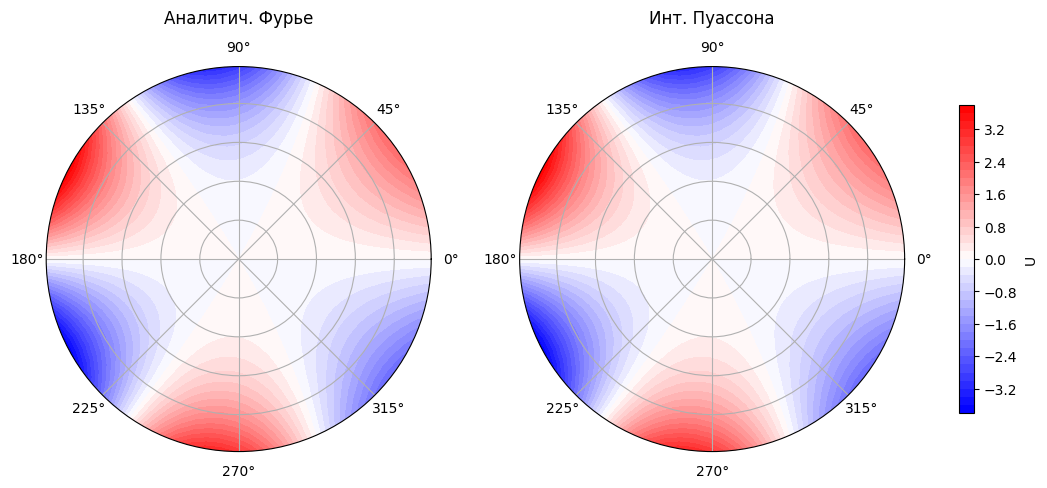

In [36]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5),
                                subplot_kw={'projection': 'polar'})

vmin, vmax = U_an.min(), U_an.max()

c1 = ax1.contourf(PHI, R, U_an, levels=40, cmap='bwr', vmin=vmin, vmax=vmax)
ax1.set_title('Аналитич. Фурье', pad=12)
ax1.set_yticklabels([])

c2 = ax2.contourf(PHI, R, U_po, levels=40, cmap='bwr', vmin=vmin, vmax=vmax)
ax2.set_title('Инт. Пуассона', pad=12)
ax2.set_yticklabels([])

fig.colorbar(c2, ax=[ax1, ax2], shrink=0.8, label='U')
plt.show()